# 17. Letter Combinations of a Phone Number
**Difficulty:** 🟡 Medium · **Topic:** Backtracking · **Pattern:** [Combinations](README.md) · **LeetCode:** https://leetcode.com/problems/letter-combinations-of-a-phone-number/

## 💡 Concepts

**Core concept(s):** **Backtracking over a fixed sequence of choice sets** — position `i` of the answer is one letter from the set of digit `i`.

**Why it applies here:**
- Every digit maps to 3 or 4 letters (`"2" -> "abc"`, `"7" -> "pqrs"`).
- An answer picks **one letter per digit, in digit order**. That is a tree: level `i` branches over the letters of `digits[i]`.
- We must list *every* leaf of that tree, so there is nothing to prune: the work is the size of the output.

**Key intuition:**
- It is the Combinations template with the start index replaced by the **position** `i`: the choices at level `i` come from `digits[i]`, not from "the rest of the array".
- No duplicates can occur: different digits are different positions, so no skip rule is needed.
- Branching factors multiply: `"79"` gives `4 × 4 = 16` strings.

---

### 📚 What is a Hash Map?
- A hash map (Python `dict`) stores key → value pairs, and finds a key's value directly via a hash function.
- Insert and lookup are **O(1) on average**.
- **In Python:** `PHONE = {"2": "abc", ...}`; `PHONE[d]` gives the letters for digit `d`.

### 📚 What is Recursion?
- A function that calls itself on a smaller problem, with a **base case** that stops it.
- Here each call handles one digit; the base case is "all digits used" (`i == len(digits)`).
- **Space:** the call stack is `n` calls deep (`n` = number of digits).

### 📚 What is Backtracking?
- Build the answer in a shared `path`: **choose** (`append` a letter), **explore** (recurse to the next digit), **un-choose** (`pop`).
- It walks a **tree of choices** depth-first; each root-to-leaf path is one answer.
- **Complexity:** the tree has up to `4^n` leaves, so the time is exponential in `n` — but that is the size of the output, so nothing can do better.
- **In Python:** `path` as a `list` of characters, `"".join(path)` to save a string at a leaf.

### 📚 What is the Cartesian product (the iterative view)?
- The answer is the product `letters(d1) × letters(d2) × ... × letters(dn)`.
- It can be built **level by level** like a BFS: start with `[""]`, and for each digit extend every partial string by every letter of that digit.
- **In Python:** a list comprehension `[p + ch for p in combos for ch in PHONE[d]]` (or `itertools.product`).

---

**Prerequisite knowledge:**
- The start-index template from [Combination Sum](combination_sum.ipynb) (here the "start" is simply the digit position).

## 📝 Problem

Given a string `digits` containing digits from `2` to `9`, return all letter combinations the number could represent, using the telephone keypad mapping. Return them in any order. An empty input returns an empty list.

```
2: abc   3: def   4: ghi   5: jkl
6: mno   7: pqrs  8: tuv   9: wxyz
```

**Example 1**
```
digits = "23"  ->  ["ad", "ae", "af", "bd", "be", "bf", "cd", "ce", "cf"]
```

**Example 2**
```
digits = ""  ->  []
```

**Example 3**
```
digits = "2"  ->  ["a", "b", "c"]
```

**Constraints:** `0 <= len(digits) <= 4`, `digits[i]` in `'2'..'9'`.

> Only two meaningfully different approaches exist, and both are optimal in Big-O (the output itself has up to `4^n` strings): build level by level (iterative product), and backtracking depth-first (the [Combinations](README.md) template).

In [1]:
from typing import List

PHONE = {"2": "abc", "3": "def", "4": "ghi", "5": "jkl",
         "6": "mno", "7": "pqrs", "8": "tuv", "9": "wxyz"}

### Approach 1 — Iterative: extend every prefix, one digit at a time

**Idea:**
1. Start with one empty prefix: `combos = [""]`.
2. For each digit, replace `combos` by every prefix extended with every letter of that digit.
3. After the last digit, `combos` holds all answers.

**Time complexity:** `O(n · 4^n)` — the last round builds up to `4^n` strings of length `n` (earlier rounds are smaller, a geometric sum).

**Space complexity:** `O(n · 4^(n-1))` extra — the previous round's list of prefixes is kept while the next one is built (plus the output itself).

In [2]:
def letter_combinations_iterative(digits: str) -> List[str]:
    if not digits:
        return []                          # no digits -> no combinations (not [""])
    combos = [""]                          # one empty prefix to extend
    for d in digits:
        combos = [prefix + ch              # every prefix so far ...
                  for prefix in combos
                  for ch in PHONE[d]]      # ... times every letter of this digit
    return combos

### Approach 2 — Backtracking, one digit per level (optimal · pattern template)

**Idea:** the [Combinations](README.md) template, where level `i` loops over the letters of `digits[i]`.
1. `backtrack(i)`: if `i == len(digits)`, the path has one letter per digit — save `"".join(path)`.
2. Otherwise, for each letter of `digits[i]`: choose it, recurse to `i + 1`, pop it.
3. Recursing with `i + 1` is the "start index": each level owns one digit, so no combination can repeat.

**Time complexity:** `O(n · 4^n)` — up to `4^n` leaves, each joined into a string of length `n`. Same as Approach 1: it is the size of the output.

**Space complexity:** `O(n)` extra — the recursion depth and `path` are both `n`; output aside.

> Same Big-O as Approach 1. Backtracking is the interview target because it is the same template as the other problems in this pattern and needs only `O(n)` working memory. In CPython the iterative list comprehension is faster by a constant factor (see the benchmark).

In [3]:
def letter_combinations_backtrack(digits: str) -> List[str]:
    if not digits:
        return []
    out, path = [], []
    def backtrack(i):                      # i = which digit we are choosing a letter for
        if i == len(digits):
            out.append("".join(path))      # one letter per digit -> a full combination
            return
        for ch in PHONE[digits[i]]:        # the choices at this level come from digit i
            path.append(ch)                # choose
            backtrack(i + 1)               # explore the next digit
            path.pop()                     # un-choose
    backtrack(0)
    return out

In [4]:
# Correctness check
import random
from itertools import product

tests = [
    ("23", ["ad", "ae", "af", "bd", "be", "bf", "cd", "ce", "cf"]),   # LeetCode example 1
    ("", []),                                                         # LeetCode example 2
    ("2", ["a", "b", "c"]),                                           # LeetCode example 3
    ("79", sorted(a + b for a in "pqrs" for b in "wxyz")),            # two 4-letter digits: 16
]
for digits, exp in tests:
    a = letter_combinations_iterative(digits)
    b = letter_combinations_backtrack(digits)
    print(f"{digits!r:6} -> {len(b):>2} combos: {b[:9]}")
    assert sorted(a) == sorted(b) == sorted(exp), f"mismatch on {digits!r}"

# Randomised cross-check against itertools.product
rng = random.Random(17)
for _ in range(200):
    digits = "".join(rng.choice("23456789") for _ in range(rng.randint(1, 4)))
    ref = sorted("".join(t) for t in product(*(PHONE[d] for d in digits)))
    assert sorted(letter_combinations_iterative(digits)) == sorted(letter_combinations_backtrack(digits)) == ref, digits
print("200 random digit strings: both approaches match itertools.product")

print("\nAll tests passed")

'23'   ->  9 combos: ['ad', 'ae', 'af', 'bd', 'be', 'bf', 'cd', 'ce', 'cf']
''     ->  0 combos: []
'2'    ->  3 combos: ['a', 'b', 'c']
'79'   -> 16 combos: ['pw', 'px', 'py', 'pz', 'qw', 'qx', 'qy', 'qz', 'rw']
200 random digit strings: both approaches match itertools.product

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. The output has `4^n` strings when every digit is a 4-letter key, so the worst case is `digits = "7979..."`. Doubling `n` would multiply the work by `4^n` — far too fast to time — so we grow `n` by **+1 digit** per step. The ratio column is therefore **per +1 digit, not per doubling** (ignore the helper's doubling footer).

| Approach | Expected ratio per +1 digit |
|----------|-----------------------------|
| Iterative product | ≈ **4×** (four times as many strings, each one letter longer) |
| Backtracking | ≈ **4×** (same) |

Both rows should show the same ≈4× growth; only the constant differs.


iterative product
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        4 |       0.01 |           n/a
        5 |       0.04 |         3.65x
        6 |       0.15 |         3.96x
        7 |       0.59 |         3.90x
        8 |       2.82 |         4.80x

backtracking
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        4 |       0.03 |           n/a
        5 |       0.11 |         3.95x
        6 |       0.44 |         3.94x
        7 |       1.91 |         4.30x
        8 |       8.04 |         4.20x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


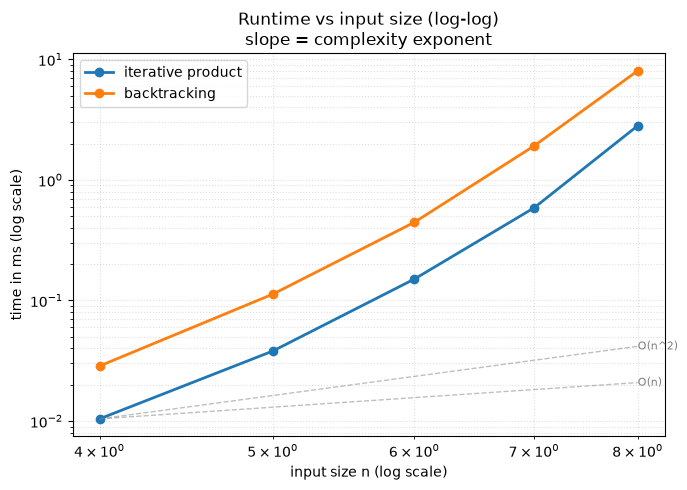

In [5]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    return (("79" * n)[:n],)           # every digit has 4 letters -> 4^n combinations
solutions = {
    "iterative product": letter_combinations_iterative,
    "backtracking": letter_combinations_backtrack,
}
sizes = [4, 5, 6, 7, 8]                # number of digits, +1 per step (8 digits -> 65,536 strings)

_ = benchmark(solutions, make_worst_case, sizes, repeats=3, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Combinations](README.md) — the start-index template where the index is the digit position: level `i` loops over the letters of `digits[i]`, then recurses with `i + 1`.
- **"One choice per position, from a fixed menu"** → a product tree. Its size is the product of the branching factors, and listing it is optimal.
- **Two views of the same tree:** depth-first backtracking (`O(n)` working memory) and level-by-level product (keeps a whole level of prefixes).
- **No pruning, no dedupe:** every leaf is a valid, distinct answer, so the template's `break` / `continue` lines simply disappear.
- **Signal:** "all possible strings", "each digit maps to letters", "every combination of one choice per slot".
- **Related problems:** Generate Parentheses (same tree, with a validity rule), Combination Sum (the same template with a start index), Letter Case Permutation, Word Break II.
- **Common pitfalls:**
  1. Returning `[""]` for empty input instead of `[]`.
  2. Forgetting `path.pop()` (or building strings with `+=` on a shared variable without undoing).
  3. Hard-coding 3 letters per key: `7` and `9` have four.